In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/busygeek/smx-concentration/SMX_concentration.csv
/kaggle/input/datasets/busygeek/smx-concentration/SMX_occurrence.csv


In [2]:
df_occ=pd.read_csv("/kaggle/input/datasets/busygeek/smx-concentration/SMX_occurrence.csv")
df_conc=pd.read_csv("/kaggle/input/datasets/busygeek/smx-concentration/SMX_concentration.csv")

In [3]:
df_occ.shape

df_conc.shape

(871, 37)

In [4]:
df_occ.shape

(1502, 41)

In [5]:
df_occ.head()

,site_id,country,latitude,longitude,sampling_date,water_matrix,concentration_ng_L,LoD,LoQ,detection_status,...,dist_to_urban_area,pH,EC,TOC,COD,nutrients,turbidity,suspended_solids,Y_occ,Y_det
0,771,Italy,45.551944,8.973056,2006-12-13,river/lake,131.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
1,772,Italy,45.518889,9.041944,2006-12-13,river/lake,117.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
2,773,Italy,45.296667,9.388889,2006-06-29,river/lake,60.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
3,774,Italy,45.538056,9.182222,2006-10-04,river/lake,49.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
4,775,Italy,45.889167,11.605000,2006-06-29,river/lake,13.0,0.5,1.0,quantified,...,0.141435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1


In [6]:
df_conc.head()

,site_id,country,latitude,longitude,sampling_date,water_matrix,concentration_ng_L,month,year,day_of_year,...,dist_to_WWTP,dist_to_urban_area,pH,EC,TOC,COD,nutrients,turbidity,suspended_solids,Y_conc
0,771,Italy,45.551944,8.973056,2006-12-13,river/lake,131.0,12.0,2006.0,347.0,...,1.245786,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.120574
1,772,Italy,45.518889,9.041944,2006-12-13,river/lake,117.0,12.0,2006.0,347.0,...,4.349366,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.071882
2,773,Italy,45.296667,9.388889,2006-06-29,river/lake,60.0,6.0,2006.0,180.0,...,0.782883,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.785330
3,774,Italy,45.538056,9.182222,2006-10-04,river/lake,49.0,10.0,2006.0,277.0,...,1.940980,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.698970
4,775,Italy,45.889167,11.605000,2006-06-29,river/lake,13.0,6.0,2006.0,180.0,...,8.793537,0.141435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.146128


In [7]:
missing = pd.DataFrame({
    'Missing Count': df_occ.isnull().sum(),
    'Missing Percentage': (df_occ.isnull().sum() / len(df_occ)) * 100
})

missing = missing.sort_values('Missing Percentage', ascending=False)

print(missing)

                     Missing Count  Missing Percentage
COD                           1502          100.000000
turbidity                     1498           99.733688
nutrients                     1469           97.802929
TOC                           1416           94.274301
suspended_solids              1406           93.608522
pH                            1349           89.813582
EC                            1331           88.615180
rainfall_anomaly               249           16.577896
air_temperature                225           14.980027
evapotranspiration             225           14.980027
rainfall_1d                    225           14.980027
rainfall_7d                    225           14.980027
rainfall_30d                   225           14.980027
population_density             162           10.785619
month_sin                      144            9.587217
season                         144            9.587217
month                          144            9.587217
sampling_d

In [8]:
missing = pd.DataFrame({
    'Missing Count': df_conc.isnull().sum(),
    'Missing Percentage': (df_conc.isnull().sum() / len(df_conc)) * 100
})

missing = missing.sort_values('Missing Percentage', ascending=False)

print(missing)

                     Missing Count  Missing Percentage
COD                            871          100.000000
turbidity                      869           99.770379
nutrients                      848           97.359357
TOC                            798           91.618829
suspended_solids               789           90.585534
pH                             750           86.107922
EC                             739           84.845006
rainfall_anomaly                90           10.332951
rainfall_1d                     75            8.610792
air_temperature                 75            8.610792
rainfall_30d                    75            8.610792
evapotranspiration              75            8.610792
rainfall_7d                     75            8.610792
season                          59            6.773823
month_cos                       59            6.773823
month                           59            6.773823
month_sin                       59            6.773823
sampling_d

In [9]:
df_occ = df_occ.drop(columns=df_occ.columns[df_occ.isnull().mean() >= 0.70])

In [10]:
df_conc = df_conc.drop(columns=df_conc.columns[df_conc.isnull().mean() >= 0.70])

In [11]:
df_occ.drop(columns=['pct_industrial_land','day_of_year'], inplace=True)
df_conc.drop(columns=['pct_industrial_land', 'day_of_year'], inplace=True)


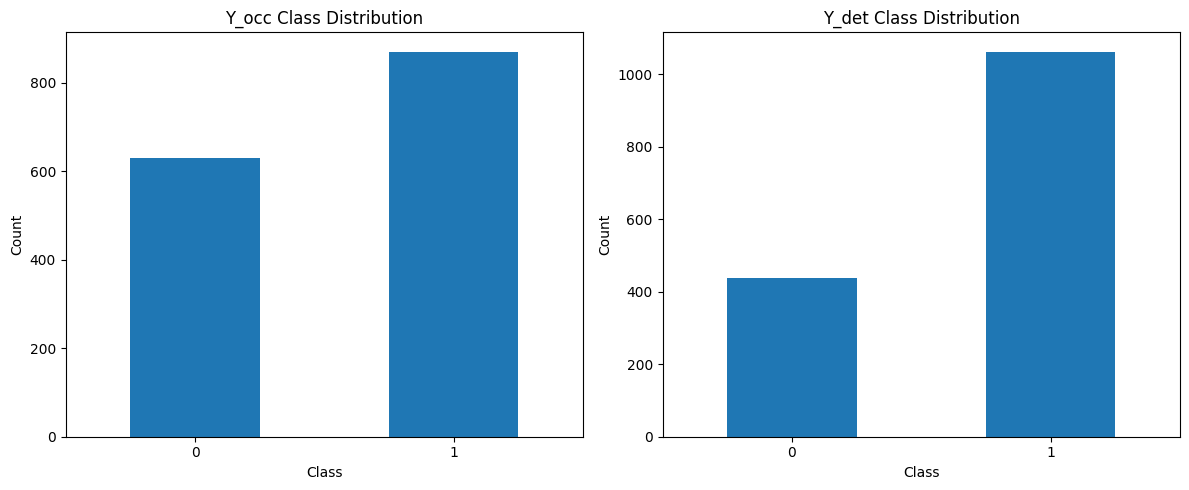

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ---------------- Y_occ ----------------
df_occ['Y_occ'].value_counts().sort_index().plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Y_occ Class Distribution')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['0', '1'], rotation=0)

# ---------------- Y_det ----------------
df_occ['Y_det'].value_counts().sort_index().plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Y_det Class Distribution')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(['0', '1'], rotation=0)

plt.tight_layout()
plt.show()

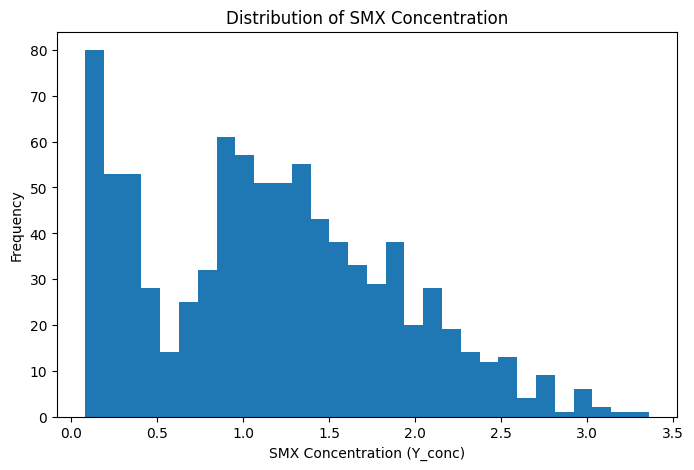

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_conc['Y_conc'].dropna(),
    bins=30
)

plt.xlabel('SMX Concentration (Y_conc)')
plt.ylabel('Frequency')
plt.title('Distribution of SMX Concentration')

plt.show()

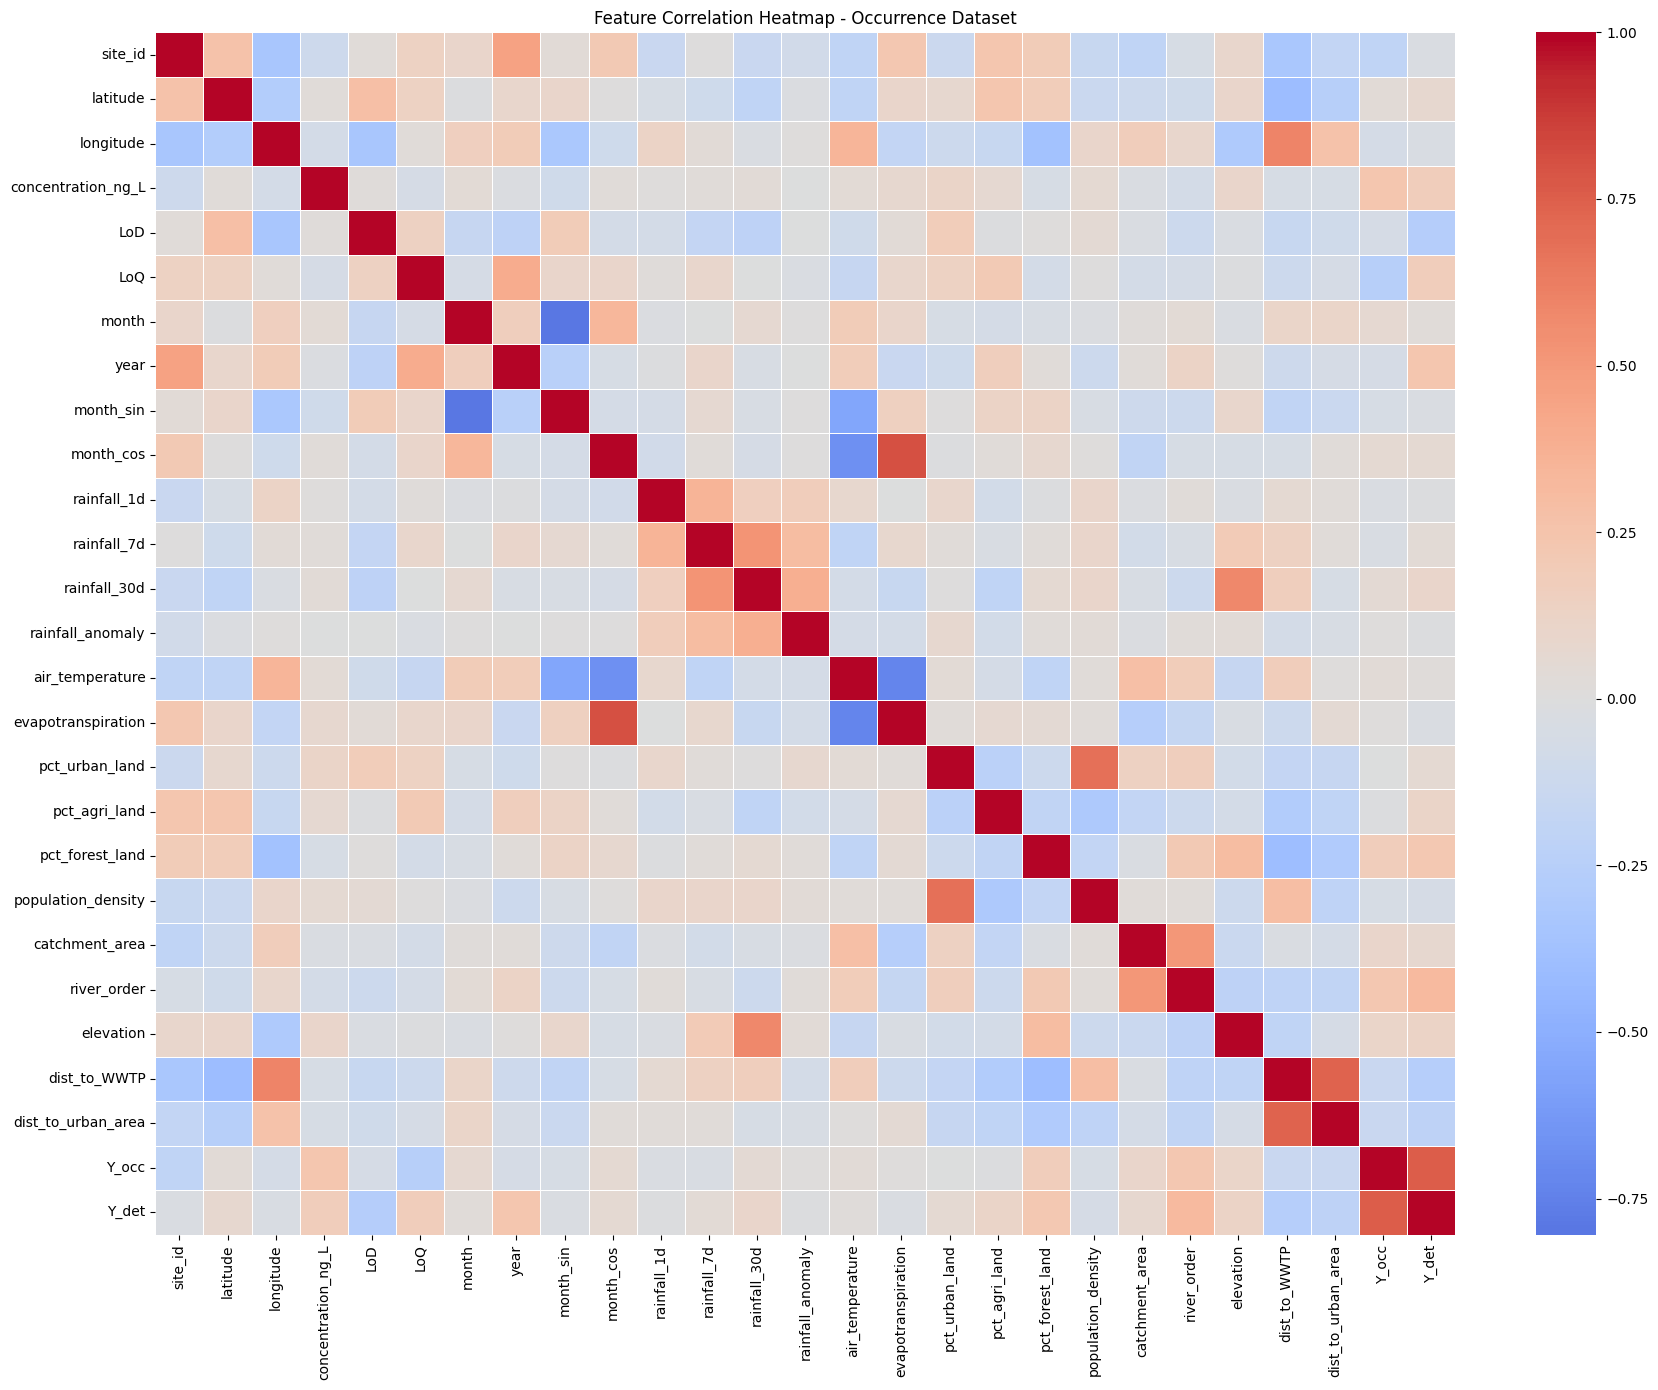

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_occ = df_occ.select_dtypes(include='number')

# Correlation matrix
corr_occ = numeric_occ.corr()

# Plot
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_occ,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap - Occurrence Dataset')
plt.tight_layout()
plt.show()

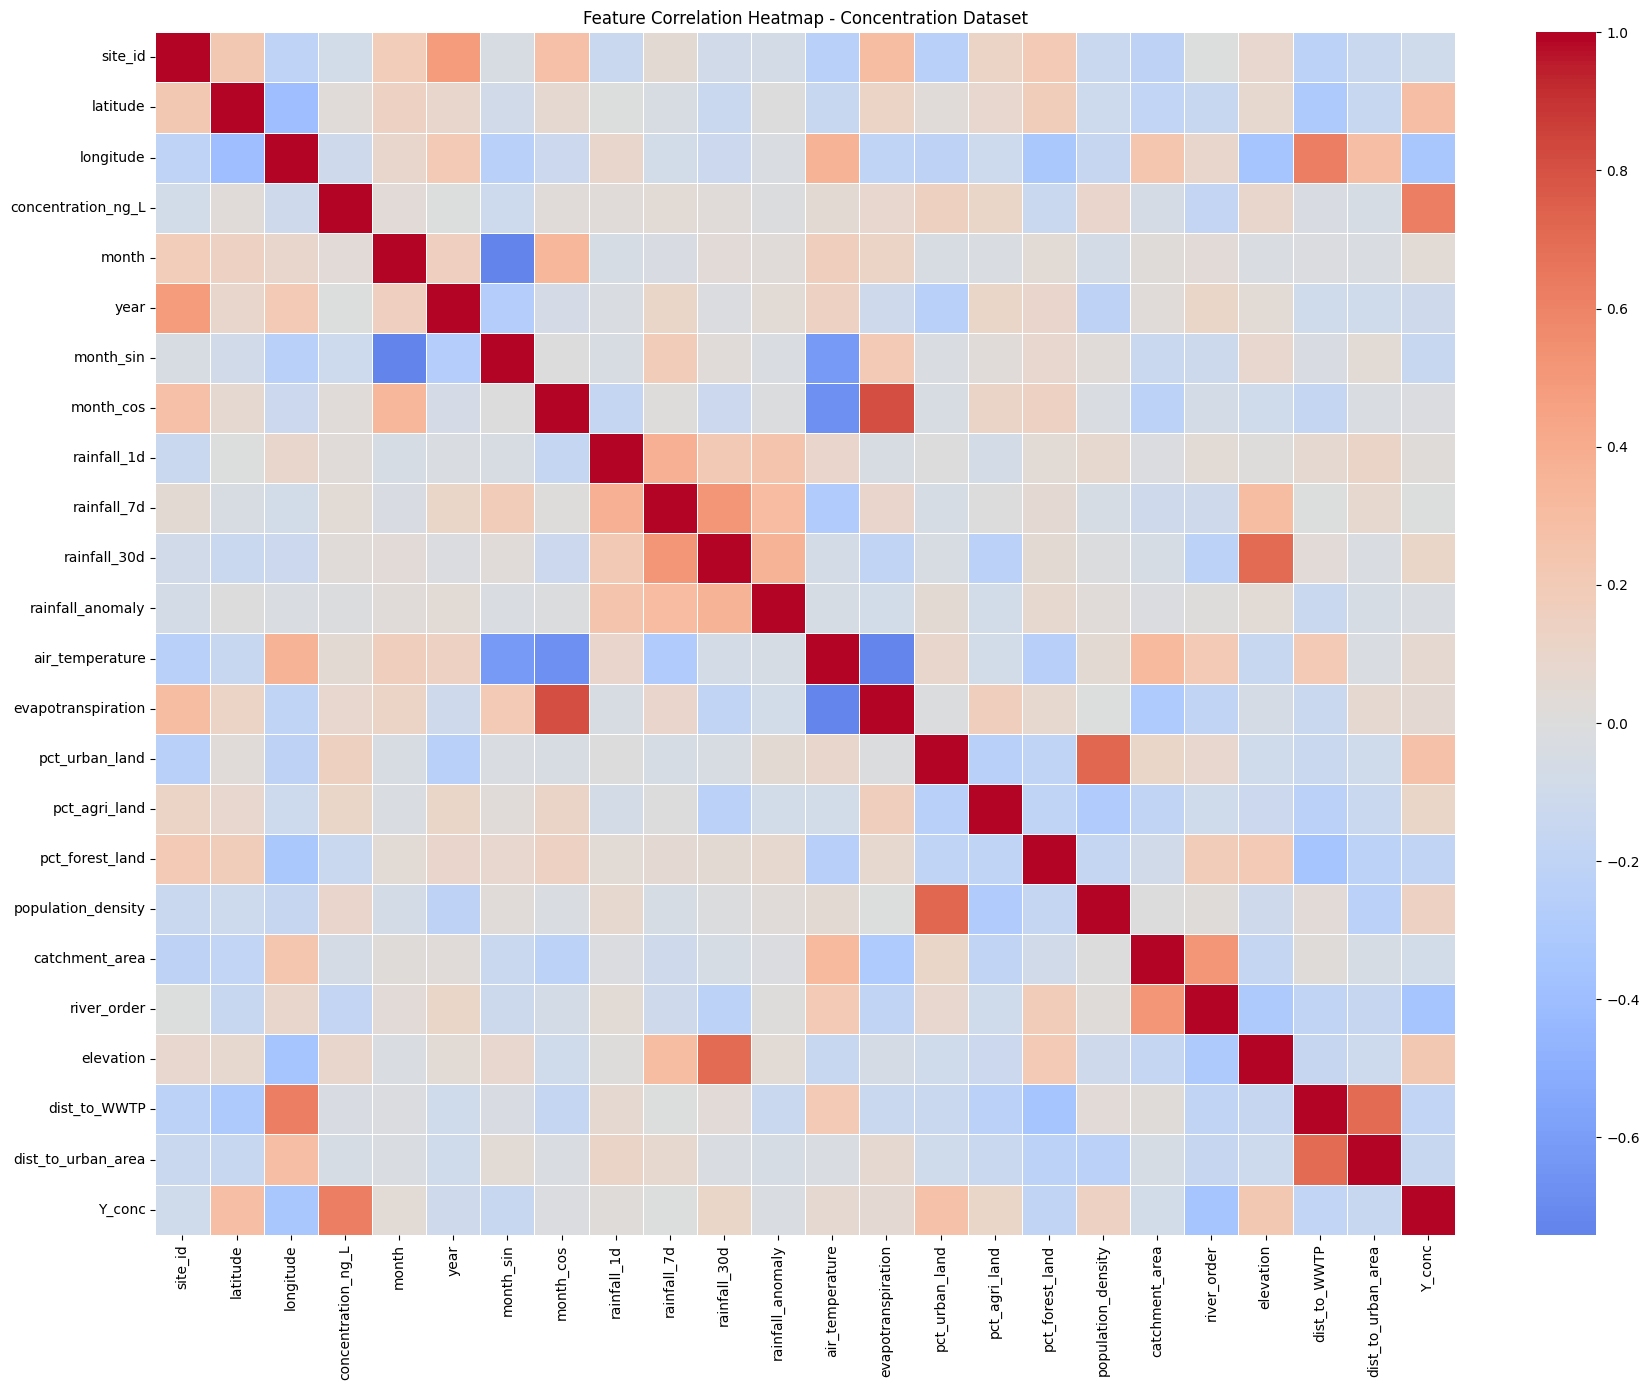

In [15]:
# Select numerical columns
numeric_conc = df_conc.select_dtypes(include='number')

# Correlation matrix
corr_conc = numeric_conc.corr()

# Plot
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_conc,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap - Concentration Dataset')
plt.tight_layout()
plt.show()

In [16]:
# Strong feature-feature correlations
corr = df_conc.select_dtypes(include='number').corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

strong_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={
        'level_0': 'Feature 1',
        'level_1': 'Feature 2',
        0: 'Correlation'
    })
)

strong_pairs['Abs_Correlation'] = strong_pairs['Correlation'].abs()

strong_pairs = strong_pairs.sort_values(
    'Abs_Correlation',
    ascending=False
)

print(strong_pairs[strong_pairs['Abs_Correlation'] >= 0.7])

           Feature 1           Feature 2  Correlation  Abs_Correlation
145        month_cos  evapotranspiration     0.815745         0.815745
87             month           month_sin    -0.740713         0.740713
210  air_temperature  evapotranspiration    -0.731243         0.731243
233   pct_urban_land  population_density     0.714492         0.714492
273     dist_to_WWTP  dist_to_urban_area     0.706929         0.706929
194     rainfall_30d           elevation     0.706670         0.706670


In [28]:
!pip install -q optuna imbalanced-learn xgboost

# Applying paper Sections 3.6 – 3.13 to the SMX notebook

**Important fix first.** The previous modelling cells fed `concentration_ng_L`, `detection_status`, `LoD`, `LoQ` and `sampling_date` into the occurrence model. `Y_occ` is derived directly from `detection_status`, so those columns *are* the answer. This is why the SMOTE model scored 1.000 on everything. All of them (and `Y_det`) are removed in Section 3.6, and the random stratified split is replaced by the grouped (country-level) split required by Section 3.11.

Everything below follows the paper:

| Section | What is implemented |
|---|---|
| 3.6 | Dataset A (occurrence) and Dataset B (log10(C+1), quantified only) |
| 3.7 | Baselines: logistic regression, GAM-style spline logistic, linear regression, Tobit, mixed-effects |
| 3.8 | RF, XGBoost, CatBoost, SVM/SVR, EBM |
| 3.9 | Class weights, SMOTE sensitivity (training data only), PR-AUC, validation-set threshold |
| 3.10 | Optuna search (paper ranges), validation PR-AUC / RMSE |
| 3.11 | Grouped 70/15/15 split, leave-one-country-out, temporal, water-matrix transfer |
| 3.12 | Full metric set, calibration slope and plot, ng/L back-transformed errors |
| 3.13 | Quantile regression + conformal intervals, calibrated probabilities, uncertainty categories |

In [29]:
import warnings, re
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import optimize, stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier, CatBoostRegressor
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna

try:
    import statsmodels.api as sm
    HAS_SM = True
except ImportError:
    HAS_SM = False
try:
    from interpret.glassbox import ExplainableBoostingClassifier
    HAS_EBM = True
except Exception:
    HAS_EBM = False
print('statsmodels:', HAS_SM, '| interpret (EBM):', HAS_EBM)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style('whitegrid')

# ------------------------------- CONFIG -------------------------------------
RANDOM_STATE        = 42
N_TRIALS            = 50      # paper: 50-100 per model. Use 10 for a quick dry run.
N_JOBS              = -1
MIN_COUNTRY_N       = 25      # LOCO: minimum rows for a country to be held out
MIN_MATRIX_N        = 50      # matrix-transfer: minimum rows for a held-out matrix
INCLUDE_COUNTRY     = False   # country one-hot cannot transfer to unseen countries
INCLUDE_COORDS      = False   # lat/lon act as country/site identifiers
THRESHOLD_CRITERION = 'balanced_accuracy'   # or 'f1'
CALIBRATION         = 'isotonic'            # or 'platt'
LOCO_MODELS         = ['Logistic Regression', 'Random Forest', 'XGBoost', 'CatBoost']

statsmodels: True | interpret (EBM): False


## 3.6 Construction of modelling datasets

* **Dataset A (occurrence):** one row per sample, target `Y_occ`.
* **Dataset B (conditional concentration):** quantified samples only, target `Y_conc = log10(C + 1)`.

Columns removed from the feature matrices: target-derived or method-dependent columns (`Y_occ`, `Y_det`, `Y_conc`, `concentration_ng_L`, `detection_status`, `LoD`, `LoQ`), identifiers (`site_id`, `sampling_date`) and, by default, `country` and coordinates (they identify the group being held out in Section 3.11). The water-quality columns were already dropped earlier because they are 85–100 % missing.

In [30]:
df_occ  = df_occ.reset_index(drop=True)
df_conc = df_conc.reset_index(drop=True)

# How is Y_occ defined? (below-LoQ detections are labelled 0 if this shows them under Y_occ = 0)
print(pd.crosstab(df_occ['detection_status'], df_occ['Y_occ']))
print('\nY_conc == log10(C+1)?', np.allclose(df_conc['Y_conc'], np.log10(df_conc['concentration_ng_L'] + 1)))

LEAKY_OR_ID = ['Y_occ', 'Y_det', 'Y_conc', 'site_id', 'sampling_date',
               'concentration_ng_L', 'detection_status', 'LoD', 'LoQ']
extra_drop = []
if not INCLUDE_COUNTRY: extra_drop.append('country')
if not INCLUDE_COORDS:  extra_drop += ['latitude', 'longitude']

XA_full = df_occ.drop(columns=LEAKY_OR_ID + extra_drop, errors='ignore')
XB_full = df_conc.drop(columns=LEAKY_OR_ID + extra_drop, errors='ignore')
FEATURES = [c for c in XA_full.columns if c in XB_full.columns]   # same feature set for A and B

X_occ,  y_occ  = XA_full[FEATURES].copy(), df_occ['Y_occ'].astype(int)
X_conc, y_conc = XB_full[FEATURES].copy(), df_conc['Y_conc'].astype(float)

print(f'\nDataset A: {X_occ.shape}, prevalence of Y_occ = {y_occ.mean():.3f}')
print(f'Dataset B: {X_conc.shape}, Y_conc mean = {y_conc.mean():.3f}')
print('Features:', FEATURES)

# Leakage guard: no single feature should separate the classes almost perfectly
def univariate_auc_scan(X, y, top=8):
    rows = []
    for c in X.select_dtypes(include=np.number).columns:
        m = X[c].notna()
        if m.sum() > 20 and y[m].nunique() == 2:
            a = roc_auc_score(y[m], X.loc[m, c])
            rows.append((c, max(a, 1 - a)))
    return (pd.DataFrame(rows, columns=['feature', 'AUC (best direction)'])
            .sort_values('AUC (best direction)', ascending=False).head(top))
print('\nTop single-feature AUCs (anything above ~0.9 would signal leakage):')
print(univariate_auc_scan(X_occ, y_occ).round(3).to_string(index=False))

Y_occ                 0    1
detection_status            
detected_below_loq  192    0
non_detect          439    0
quantified            0  871

Y_conc == log10(C+1)? True

Dataset A: (1502, 21), prevalence of Y_occ = 0.580
Dataset B: (871, 21), Y_conc mean = 1.163
Features: ['water_matrix', 'month', 'year', 'season', 'month_sin', 'month_cos', 'rainfall_1d', 'rainfall_7d', 'rainfall_30d', 'rainfall_anomaly', 'air_temperature', 'evapotranspiration', 'pct_urban_land', 'pct_agri_land', 'pct_forest_land', 'population_density', 'catchment_area', 'river_order', 'elevation', 'dist_to_WWTP', 'dist_to_urban_area']

Top single-feature AUCs (anything above ~0.9 would signal leakage):
           feature  AUC (best direction)
    catchment_area                 0.636
       river_order                 0.632
   pct_forest_land                 0.620
      dist_to_WWTP                 0.591
         elevation                 0.560
dist_to_urban_area                 0.546
       rainfall_7d            

### Shared utilities (preprocessing, model factory, metrics, threshold selection)
The metric definitions here are the Section 3.12 formulas; the formal reporting tables are in 3.12.

In [31]:
cat_cols = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(X_occ[c])]
num_cols = [c for c in FEATURES if c not in cat_cols]
print('categorical:', cat_cols, '\nnumeric:', len(num_cols))

def make_prep(scale=False, spline=False):
    num_steps = [('imp', SimpleImputer(strategy='median'))]
    if spline: num_steps.append(('spline', SplineTransformer(n_knots=5, degree=3, extrapolation='constant')))
    if scale:  num_steps.append(('sc', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ])

SCALED = {'Logistic Regression', 'GAM (spline logistic)', 'SVM', 'SVR', 'Linear Regression'}

DEFAULT_PARAMS = {
    ('cls', 'Random Forest'): dict(n_estimators=500, max_depth=8, min_samples_leaf=5),
    ('cls', 'XGBoost'):       dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8),
    ('cls', 'CatBoost'):      dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=5),
    ('cls', 'SVM'):           dict(C=1.0, gamma=0.01),
    ('cls', 'EBM'):           dict(),
    ('reg', 'Random Forest'): dict(n_estimators=500, max_depth=8, min_samples_leaf=5),
    ('reg', 'XGBoost'):       dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8),
    ('reg', 'CatBoost'):      dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=5),
    ('reg', 'SVR'):           dict(C=1.0, gamma=0.01, epsilon=0.1),
}
BEST = dict(DEFAULT_PARAMS)          # overwritten by Optuna in Section 3.10
def params_for(task, name): return BEST.get((task, name), {})

def make_estimator(name, task, params=None, y_train=None, svm_probability=True):
    p = dict(params or {})
    if task == 'cls':
        if name in ('Logistic Regression', 'GAM (spline logistic)'):
            return LogisticRegression(max_iter=5000, class_weight='balanced',
                                      C=p.pop('C', 1.0 if name == 'Logistic Regression' else 0.3), **p)
        if name == 'Random Forest':
            return RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'XGBoost':
            spw = (np.asarray(y_train) == 0).sum() / max((np.asarray(y_train) == 1).sum(), 1)
            return XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', colsample_bytree=0.8,
                                 random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'CatBoost':
            return CatBoostClassifier(loss_function='Logloss', auto_class_weights='Balanced', verbose=False,
                                      random_seed=RANDOM_STATE, allow_writing_files=False, thread_count=-1, **p)
        if name == 'SVM':
            return SVC(kernel='rbf', class_weight='balanced', probability=svm_probability,
                       random_state=RANDOM_STATE, **p)
        if name == 'EBM':
            return ExplainableBoostingClassifier(random_state=RANDOM_STATE, **p)
    else:
        if name == 'Linear Regression': return LinearRegression(**p)
        if name == 'Random Forest':
            return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'XGBoost':
            return XGBRegressor(objective='reg:squarederror', colsample_bytree=0.8,
                                random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'CatBoost':
            return CatBoostRegressor(loss_function='RMSE', verbose=False, random_seed=RANDOM_STATE,
                                     allow_writing_files=False, thread_count=-1, **p)
        if name == 'SVR': return SVR(kernel='rbf', **p)
    raise ValueError(f'unknown model {name} / {task}')

def make_pipe(name, task, params=None, y_train=None, svm_probability=True):
    prep = make_prep(scale=name in SCALED, spline=(name == 'GAM (spline logistic)'))
    return Pipeline([('prep', prep),
                     ('model', make_estimator(name, task, params, y_train, svm_probability))])

def predict_cls(pipe, X): return pipe.predict_proba(X)[:, 1]
def predict_reg(pipe, X): return np.clip(pipe.predict(X), 0, None)    # log10(C+1) >= 0

# ------------------------------ metrics (3.12) -------------------------------
def calibration_slope(y, p, eps=1e-6):
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    z = np.log(p / (1 - p)).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(z, y)
    return float(lr.coef_[0][0]), float(lr.intercept_[0])

def expected_calibration_error(y, p, n_bins=10):
    y, p = np.asarray(y), np.asarray(p)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))

def classification_metrics(y_true, prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int); prob = np.asarray(prob, float)
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        'Accuracy': accuracy_score(y_true, pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, pred) if both else np.nan,
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, prob) if both else np.nan,
        'PR-AUC': average_precision_score(y_true, prob) if both else np.nan,
        'Brier': brier_score_loss(y_true, prob),
        'Cal. slope': calibration_slope(y_true, prob)[0] if both else np.nan,
        'ECE': expected_calibration_error(y_true, prob),
        'Threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_pred - y_true
    c_true = 10 ** y_true - 1
    c_pred = 10 ** np.clip(y_pred, 0, None) - 1          # back-transform to ng/L
    return {
        'RMSE': float(np.sqrt(np.mean(err ** 2))), 'MAE': float(np.mean(np.abs(err))),
        'R2': r2_score(y_true, y_pred), 'Bias (log10)': float(err.mean()),
        'RMSE (ng/L)': float(np.sqrt(np.mean((c_pred - c_true) ** 2))),
        'MAE (ng/L)': float(np.mean(np.abs(c_pred - c_true))),
        'Bias (ng/L)': float(np.mean(c_pred - c_true)),
        'Median abs. error (ng/L)': float(np.median(np.abs(c_pred - c_true))),
    }

# ---------------------- threshold selection (3.9) ----------------------------
def select_threshold(y_true, prob, criterion='balanced_accuracy', grid=None):
    grid = np.arange(0.05, 0.951, 0.01) if grid is None else grid
    y_true = np.asarray(y_true).astype(int); prob = np.asarray(prob, float)
    scores = np.array([
        balanced_accuracy_score(y_true, (prob >= t).astype(int)) if criterion == 'balanced_accuracy'
        else f1_score(y_true, (prob >= t).astype(int), zero_division=0) for t in grid])
    return float(np.median(grid[scores >= scores.max() - 1e-9]))   # middle of the best plateau

categorical: ['water_matrix', 'season'] 
numeric: 19


## 3.11 (setup) Validation 1: grouped spatial split — 70 % / 15 % / 15 % of countries

All rows of a country stay together. Among many random country assignments, the one is chosen whose **row fractions are closest to 70/15/15 and whose positive-class prevalence is most similar across splits** (this avoids the problem of a validation set with a very different prevalence from the test set, which distorts threshold selection). The same country assignment is used for Dataset B.

In [32]:
def grouped_split(groups, y, fractions=(0.70, 0.15, 0.15), n_tries=5000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    groups = np.asarray(groups); y = np.asarray(y)
    ctry = pd.unique(groups); n = len(ctry)
    n_tr, n_va = int(round(fractions[0] * n)), int(round(fractions[1] * n))
    cnt = pd.Series(groups).value_counts()
    pos = pd.Series(y).groupby(groups).sum()
    best = None
    for _ in range(n_tries):
        perm = rng.permutation(ctry)
        parts = (perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:])
        if any(len(p) == 0 for p in parts): continue
        rows = [cnt[list(p)].sum() / len(groups) for p in parts]
        prev = [pos[list(p)].sum() / cnt[list(p)].sum() for p in parts]
        cost = sum(abs(r - f) for r, f in zip(rows, fractions)) + 0.5 * (max(prev) - min(prev))
        if best is None or cost < best[0]: best = (cost, parts)
    return {'train': list(best[1][0]), 'val': list(best[1][1]), 'test': list(best[1][2])}

SPLIT_COUNTRIES = grouped_split(df_occ['country'], y_occ)
ctry2split = {c: s for s, cs in SPLIT_COUNTRIES.items() for c in cs}

mask_A = {s: (df_occ['country'].map(ctry2split) == s).values for s in ('train', 'val', 'test')}
mask_B = {s: (df_conc['country'].map(ctry2split) == s).values for s in ('train', 'val', 'test')}
assert df_conc['country'].map(ctry2split).notna().all(), 'a Dataset-B country is missing from Dataset A'

XA_tr, yA_tr = X_occ.loc[mask_A['train']], y_occ.loc[mask_A['train']]
XA_va, yA_va = X_occ.loc[mask_A['val']],   y_occ.loc[mask_A['val']]
XA_te, yA_te = X_occ.loc[mask_A['test']],  y_occ.loc[mask_A['test']]
XB_tr, yB_tr = X_conc.loc[mask_B['train']], y_conc.loc[mask_B['train']]
XB_va, yB_va = X_conc.loc[mask_B['val']],   y_conc.loc[mask_B['val']]
XB_te, yB_te = X_conc.loc[mask_B['test']],  y_conc.loc[mask_B['test']]

summary = pd.DataFrame({
    s: {'countries': len(SPLIT_COUNTRIES[s]), 'rows A': int(mask_A[s].sum()),
        'prevalence A': round(float(y_occ[mask_A[s]].mean()), 3), 'rows B': int(mask_B[s].sum()),
        'mean Y_conc B': round(float(y_conc[mask_B[s]].mean()), 3)}
    for s in ('train', 'val', 'test')}).T
print(summary)
for s in ('val', 'test'): print(f'{s} countries:', SPLIT_COUNTRIES[s])

# Registries that collect predictions for the reporting sections (3.12)
CLS, REG = {}, {}
def register_cls(name, p_val, p_test):
    CLS[name] = {'val': np.asarray(p_val, float), 'test': np.asarray(p_test, float),
                 'tau': select_threshold(yA_va, p_val, THRESHOLD_CRITERION)}
def register_reg(name, pred_val, pred_test):
    REG[name] = {'val': np.clip(np.asarray(pred_val, float), 0, None),
                 'test': np.clip(np.asarray(pred_test, float), 0, None)}
def tau_for(m): return CLS.get(f'{m} (tuned)', CLS.get(m))['tau']

       countries  rows A  prevalence A  rows B  mean Y_conc B
train       19.0  1039.0         0.578   601.0          1.233
val          4.0   240.0         0.525   126.0          1.104
test         4.0   223.0         0.646   144.0          0.923
val countries: ['Czech Republic', 'Greece', 'Austria', 'Ukraine']
test countries: ['Switzerland', 'Georgia', 'Croatia', 'Portugal']


## 3.7 Baseline statistical models

Logistic regression, a GAM-style additive model (spline-expanded logistic regression — equivalent to a penalised GAM; swap in `pygam` if you prefer), linear regression, Tobit regression (using all occurrence rows, with non-quantified samples left-censored at the LoQ), and a mixed-effects model with a country random intercept (predictions for unseen countries use the fixed effects only, which is what a new region would get).

In [33]:
# ---- occurrence baselines
for name in ['Logistic Regression', 'GAM (spline logistic)']:
    pipe = make_pipe(name, 'cls', {}, yA_tr).fit(XA_tr, yA_tr)
    register_cls(name, predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))

# ---- concentration baseline: linear regression on log10(C+1)
pipe = make_pipe('Linear Regression', 'reg').fit(XB_tr, yB_tr)
register_reg('Linear Regression', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))

# ---- Tobit (left-censored normal regression), trained on ALL occurrence rows of the training countries
def fit_tobit(Z, y_obs, cens, c_pt, l2=1e-2):
    n, p = Z.shape
    A = np.hstack([np.ones((n, 1)), Z])
    ols = np.linalg.lstsq(A[~cens], y_obs[~cens], rcond=None)[0]
    s0 = np.std(y_obs[~cens] - A[~cens] @ ols) + 1e-6
    def nll(theta):
        beta, log_s = theta[:-1], theta[-1]; s = np.exp(log_s)
        mu = A @ beta
        ll = stats.norm.logpdf((y_obs[~cens] - mu[~cens]) / s).sum() - (~cens).sum() * log_s
        ll += stats.norm.logcdf((c_pt[cens] - mu[cens]) / s).sum()
        return -ll + l2 * np.sum(beta[1:] ** 2)
    res = optimize.minimize(nll, np.r_[ols, np.log(s0)], method='L-BFGS-B', options={'maxiter': 500})
    return {'beta': res.x[:-1], 'sigma': float(np.exp(res.x[-1])), 'converged': bool(res.success)}

def tobit_predict(m, Z, c0=None):
    mu = m['beta'][0] + Z @ m['beta'][1:]
    if c0 is None: return mu                                   # latent mean
    s = m['sigma']; a = (c0 - mu) / s                          # E[y | y > c0]
    return mu + s * stats.norm.pdf(a) / np.clip(stats.norm.sf(a), 1e-9, None)

occ_tr = df_occ.loc[mask_A['train']]
cens = (occ_tr['detection_status'] != 'quantified').values
c_pt = np.log10(occ_tr['LoQ'].values + 1)
y_obs = np.where(cens, c_pt, np.log10(occ_tr['concentration_ng_L'].values + 1))
prep_t = make_prep(scale=True).fit(XA_tr)
tobit = fit_tobit(prep_t.transform(XA_tr), y_obs, cens, c_pt)
c0 = float(np.median(c_pt[cens])) if cens.any() else 0.0
print(f"Tobit: converged={tobit['converged']}, sigma={tobit['sigma']:.3f}, censored share={cens.mean():.2f}")
Zva, Zte = prep_t.transform(XB_va), prep_t.transform(XB_te)
register_reg('Tobit (latent mean)', tobit_predict(tobit, Zva), tobit_predict(tobit, Zte))
register_reg('Tobit (E[y | quantified])', tobit_predict(tobit, Zva, c0), tobit_predict(tobit, Zte, c0))

# ---- mixed-effects model with country random intercept (Dataset B)
if HAS_SM:
    try:
        prep_me = make_prep(scale=True).fit(XB_tr)
        names = list(prep_me.get_feature_names_out())
        def me_design(X, keep=None):
            D = pd.DataFrame(prep_me.transform(X), columns=names)
            if keep is None:
                keep = [c for c in D.columns if D[c].std() > 1e-8]
                for c in cat_cols:                                 # drop one reference level per categorical
                    lv = [n for n in keep if n.startswith(f'cat__{c}_')]
                    if lv: keep.remove(lv[0])
            return sm.add_constant(D[keep], has_constant='add'), keep
        A_tr, keep_me = me_design(XB_tr)
        mres = sm.MixedLM(endog=yB_tr.values, exog=A_tr.values,
                          groups=df_conc.loc[mask_B['train'], 'country'].values).fit(method=['lbfgs'], reml=True)
        beta_me = np.asarray(mres.fe_params)
        register_reg('Mixed-effects (country RE)',
                     me_design(XB_va, keep_me)[0].values @ beta_me, me_design(XB_te, keep_me)[0].values @ beta_me)
        print('Mixed-effects: converged =', mres.converged, '| country variance =', float(mres.cov_re.iloc[0, 0]))
    except Exception as e:
        print('Mixed-effects model skipped:', repr(e))
else:
    print('statsmodels not available: mixed-effects baseline skipped')

print('\nBaselines, validation set (PR-AUC / RMSE):')
for k, r in CLS.items(): print(f"  {k:28s} PR-AUC={average_precision_score(yA_va, r['val']):.3f}")
for k, r in REG.items(): print(f"  {k:28s} RMSE  ={np.sqrt(mean_squared_error(yB_va, r['val'])):.3f}")

Tobit: converged=True, sigma=0.844, censored share=0.42
Mixed-effects model skipped: AttributeError("'numpy.ndarray' object has no attribute 'iloc'")

Baselines, validation set (PR-AUC / RMSE):
  Logistic Regression          PR-AUC=0.709
  GAM (spline logistic)        PR-AUC=0.701
  Linear Regression            RMSE  =0.630
  Tobit (latent mean)          RMSE  =0.840
  Tobit (E[y | quantified])    RMSE  =0.671
  Mixed-effects (country RE)   RMSE  =0.868


## 3.8 Machine-learning models

Random forest, XGBoost, CatBoost, SVM/SVR and the explainable boosting machine (EBM), trained here with regularised default settings; they are tuned in 3.10. XGBoost and CatBoost are the primary models. TabNet/MLP is **not** run: with ~1,500 occurrence rows and ~870 concentration rows the dataset is not large enough to justify it (the paper's own condition), and an LSTM is not appropriate for independent, irregular monitoring records.

In [34]:
CLS_MODELS = ['Random Forest', 'XGBoost', 'CatBoost', 'SVM'] + (['EBM'] if HAS_EBM else [])
REG_MODELS = ['Random Forest', 'XGBoost', 'CatBoost', 'SVR']

for name in CLS_MODELS:
    pipe = make_pipe(name, 'cls', params_for('cls', name), yA_tr).fit(XA_tr, yA_tr)
    register_cls(f'{name} (default)', predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))
for name in REG_MODELS:
    pipe = make_pipe(name, 'reg', params_for('reg', name)).fit(XB_tr, yB_tr)
    register_reg(f'{name} (default)', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))

print('Default models, validation set:')
for k, r in CLS.items():
    if 'default' in k: print(f"  {k:28s} PR-AUC={average_precision_score(yA_va, r['val']):.3f}  ROC-AUC={roc_auc_score(yA_va, r['val']):.3f}")
for k, r in REG.items():
    if 'default' in k: print(f"  {k:28s} RMSE ={np.sqrt(mean_squared_error(yB_va, r['val'])):.3f}")

Default models, validation set:
  Random Forest (default)      PR-AUC=0.755  ROC-AUC=0.694
  XGBoost (default)            PR-AUC=0.772  ROC-AUC=0.721
  CatBoost (default)           PR-AUC=0.754  ROC-AUC=0.695
  SVM (default)                PR-AUC=0.714  ROC-AUC=0.666
  Random Forest (default)      RMSE =0.805
  XGBoost (default)            RMSE =0.796
  CatBoost (default)           RMSE =0.782
  SVR (default)                RMSE =0.854


## 3.9 Imbalanced-data handling

* Class-weighted loss: `class_weight='balanced'` (LR, RF, SVM), `scale_pos_weight` (XGBoost), `auto_class_weights='Balanced'` (CatBoost) — already used above.
* SMOTE: **sensitivity analysis only**, applied inside the training data (it sits inside the pipeline, so validation/test rows are never oversampled). Note SMOTE interpolates the one-hot columns, which is why it is not the primary strategy.
* PR-AUC reported alongside ROC-AUC, plus balanced accuracy, precision, recall, F1.
* The threshold τ is chosen on the **validation set** (balanced accuracy by default, set `THRESHOLD_CRITERION='f1'` to change), never fixed at 0.50.

Class weights vs SMOTE (test set, validation-selected tau):
                               Balanced Accuracy  Precision  Recall     F1  \
Model                                                                        
XGBoost (default)                          0.763      0.904   0.653  0.758   
XGBoost + SMOTE (sensitivity)              0.722      0.884   0.583  0.703   

                               ROC-AUC  PR-AUC  Threshold  
Model                                                      
XGBoost (default)                0.793   0.895       0.44  
XGBoost + SMOTE (sensitivity)    0.782   0.880       0.49  

Threshold effect, XGBoost (default), test set:
                                  Accuracy  Balanced Accuracy  Precision  \
tau = 0.50                           0.740              0.784      0.948   
tau = 0.44 (validation-selected)     0.731              0.763      0.904   

                                  Recall     F1  
tau = 0.50                         0.632  0.758  
tau = 0.44

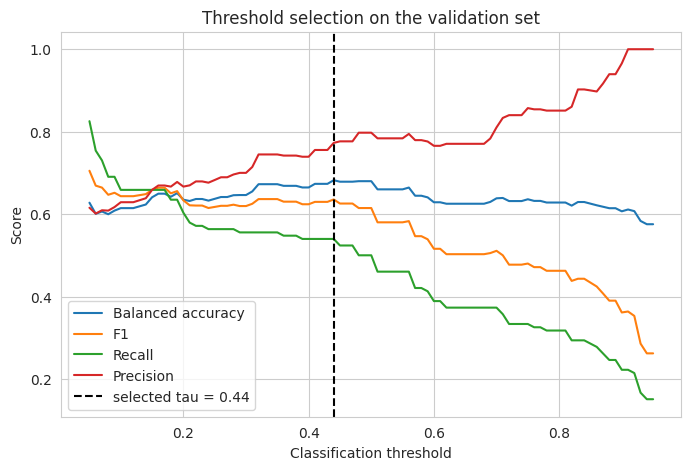

In [35]:
smote_pipe = ImbPipeline([
    ('prep', make_prep(scale=False)),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('model', XGBClassifier(eval_metric='logloss', colsample_bytree=0.8, random_state=RANDOM_STATE,
                            n_jobs=N_JOBS, **DEFAULT_PARAMS[('cls', 'XGBoost')])),
]).fit(XA_tr, yA_tr)
register_cls('XGBoost + SMOTE (sensitivity)', predict_cls(smote_pipe, XA_va), predict_cls(smote_pipe, XA_te))

rows = []
for k in ['XGBoost (default)', 'XGBoost + SMOTE (sensitivity)']:
    r = CLS[k]
    m = classification_metrics(yA_te, r['test'], r['tau']); m['Model'] = k
    rows.append(m)
print('Class weights vs SMOTE (test set, validation-selected tau):')
print(pd.DataFrame(rows).set_index('Model')[['Balanced Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Threshold']].round(3))

# Why a fixed 0.50 threshold is not used: effect on the primary model (test set)
r = CLS['XGBoost (default)']
cmp = pd.DataFrame({f'tau = 0.50': classification_metrics(yA_te, r['test'], 0.5),
                    f"tau = {r['tau']:.2f} (validation-selected)": classification_metrics(yA_te, r['test'], r['tau'])}).T
print('\nThreshold effect, XGBoost (default), test set:')
print(cmp[['Accuracy', 'Balanced Accuracy', 'Precision', 'Recall', 'F1']].round(3))

# Threshold curve on the validation set
grid = np.arange(0.05, 0.951, 0.01)
pv = r['val']
curves = pd.DataFrame({'threshold': grid,
    'Balanced accuracy': [balanced_accuracy_score(yA_va, (pv >= t).astype(int)) for t in grid],
    'F1':                [f1_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid],
    'Recall':            [recall_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid],
    'Precision':         [precision_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid]})
plt.figure(figsize=(8, 5))
for c in curves.columns[1:]: plt.plot(curves['threshold'], curves[c], label=c)
plt.axvline(r['tau'], color='k', ls='--', label=f"selected tau = {r['tau']:.2f}")
plt.xlabel('Classification threshold'); plt.ylabel('Score'); plt.title('Threshold selection on the validation set')
plt.legend(); plt.show()

## 3.10 Hyperparameter optimisation (Optuna)

Search ranges are the ones in the paper. Each trial trains on the **training countries** and is scored on the **validation countries**: PR-AUC for classification (maximise), RMSE for regression (minimise). `N_TRIALS` is set in the config cell (paper: 50–100). CatBoost with depth 10 / 1,000 iterations is the slow part: set `N_TRIALS = 10` for a dry run.

In [36]:
def sug_int(t, n, lo, hi, step=1): return t.suggest_int(n, lo, hi, step=step)

SEARCH = {
    'Random Forest': lambda t: dict(n_estimators=sug_int(t, 'n_estimators', 300, 1000, 100),
                                    max_depth=sug_int(t, 'max_depth', 5, 30),
                                    min_samples_leaf=sug_int(t, 'min_samples_leaf', 1, 20)),
    'XGBoost':       lambda t: dict(n_estimators=sug_int(t, 'n_estimators', 200, 1000, 100),
                                    max_depth=sug_int(t, 'max_depth', 3, 10),
                                    learning_rate=t.suggest_float('learning_rate', 0.01, 0.10, log=True),
                                    subsample=t.suggest_float('subsample', 0.6, 1.0)),
    'CatBoost':      lambda t: dict(iterations=sug_int(t, 'iterations', 200, 1000, 100),
                                    depth=sug_int(t, 'depth', 4, 10),
                                    learning_rate=t.suggest_float('learning_rate', 0.01, 0.10, log=True),
                                    l2_leaf_reg=t.suggest_float('l2_leaf_reg', 1, 20)),
    'SVM':           lambda t: dict(C=t.suggest_float('C', 0.1, 100, log=True),
                                    gamma=t.suggest_float('gamma', 1e-4, 1e-1, log=True)),
    'SVR':           lambda t: dict(C=t.suggest_float('C', 0.1, 100, log=True),
                                    gamma=t.suggest_float('gamma', 1e-4, 1e-1, log=True),
                                    epsilon=t.suggest_float('epsilon', 0.01, 0.50)),
}

def tune(task, name, n_trials=N_TRIALS):
    Xtr, ytr, Xva, yva = (XA_tr, yA_tr, XA_va, yA_va) if task == 'cls' else (XB_tr, yB_tr, XB_va, yB_va)
    def objective(trial):
        params = SEARCH[name](trial)
        pipe = make_pipe(name, task, params, ytr, svm_probability=False).fit(Xtr, ytr)
        if task == 'cls':
            s = pipe.decision_function(Xva) if name == 'SVM' else pipe.predict_proba(Xva)[:, 1]
            return average_precision_score(yva, s)
        return float(np.sqrt(mean_squared_error(yva, pipe.predict(Xva))))
    study = optuna.create_study(direction='maximize' if task == 'cls' else 'minimize',
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    return study

TUNING_LOG = []
for task, names in [('cls', ['Random Forest', 'XGBoost', 'CatBoost', 'SVM']),
                    ('reg', ['Random Forest', 'XGBoost', 'CatBoost', 'SVR'])]:
    for name in names:
        study = tune(task, name)
        BEST[(task, name)] = dict(study.best_params)
        TUNING_LOG.append({'task': task, 'model': name, 'best val score': round(study.best_value, 4),
                           'metric': 'PR-AUC' if task == 'cls' else 'RMSE', 'params': dict(study.best_params)})
        print(f'{task} {name}: {study.best_value:.4f}  {study.best_params}')

# Refit the tuned models on the training countries and register them
for name in ['Random Forest', 'XGBoost', 'CatBoost', 'SVM']:
    pipe = make_pipe(name, 'cls', params_for('cls', name), yA_tr).fit(XA_tr, yA_tr)
    register_cls(f'{name} (tuned)', predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))
for name in ['Random Forest', 'XGBoost', 'CatBoost', 'SVR']:
    pipe = make_pipe(name, 'reg', params_for('reg', name)).fit(XB_tr, yB_tr)
    register_reg(f'{name} (tuned)', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))
pd.DataFrame(TUNING_LOG)

cls Random Forest: 0.7762  {'n_estimators': 900, 'max_depth': 24, 'min_samples_leaf': 1}
cls XGBoost: 0.7783  {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.01295071185967868, 'subsample': 0.8844941585177181}
cls CatBoost: 0.7741  {'iterations': 200, 'depth': 6, 'learning_rate': 0.0635978451570788, 'l2_leaf_reg': 14.295715093807441}
cls SVM: 0.7216  {'C': 1.8675264892605385, 'gamma': 0.03625265676907568}
reg Random Forest: 0.7968  {'n_estimators': 600, 'max_depth': 13, 'min_samples_leaf': 4}
reg XGBoost: 0.6123  {'n_estimators': 900, 'max_depth': 6, 'learning_rate': 0.09500477945661005, 'subsample': 0.6232752753509441}
reg CatBoost: 0.7090  {'iterations': 300, 'depth': 10, 'learning_rate': 0.012590545049577122, 'l2_leaf_reg': 16.730806264969416}
reg SVR: 0.6880  {'C': 1.1203392767997962, 'gamma': 0.00010168347324668438, 'epsilon': 0.35021430690486477}


,task,model,best val score,metric,params
0,cls,Random Forest,0.7762,PR-AUC,"{'n_estimators': 900, 'max_depth': 24, 'min_sa..."
1,cls,XGBoost,0.7783,PR-AUC,"{'n_estimators': 500, 'max_depth': 5, 'learnin..."
2,cls,CatBoost,0.7741,PR-AUC,"{'iterations': 200, 'depth': 6, 'learning_rate..."
3,cls,SVM,0.7216,PR-AUC,"{'C': 1.8675264892605385, 'gamma': 0.036252656..."
4,reg,Random Forest,0.7968,RMSE,"{'n_estimators': 600, 'max_depth': 13, 'min_sa..."
5,reg,XGBoost,0.6123,RMSE,"{'n_estimators': 900, 'max_depth': 6, 'learnin..."
6,reg,CatBoost,0.7090,RMSE,"{'iterations': 300, 'depth': 10, 'learning_rat..."
7,reg,SVR,0.6880,RMSE,"{'C': 1.1203392767997962, 'gamma': 0.000101683..."


## 3.11 Spatial, temporal and external validation

**Validation 1 (grouped 70/15/15 split)** was set up above; its full results are in Section 3.12. Validations 2–4 follow. All of them reuse the tuned hyperparameters and the validation-selected thresholds τ from Validation 1. Note that the hyperparameters were tuned on the Validation-1 validation countries, so those countries are very slightly optimistic when they appear as held-out countries in Validation 2.

Compact view of Validation 1 (test countries):

In [37]:
cols = ['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC']
v1 = pd.DataFrame({k: classification_metrics(yA_te, r['test'], r['tau']) for k, r in CLS.items()}).T[cols].astype(float).round(3)
print('Validation 1, occurrence (test countries):'); print(v1.sort_values('PR-AUC', ascending=False))
v1r = pd.DataFrame({k: regression_metrics(yB_te, r['test']) for k, r in REG.items()}).T[['RMSE', 'MAE', 'R2']].astype(float).round(3)
print('\nValidation 1, concentration (test countries):'); print(v1r.sort_values('RMSE'))

Validation 1, occurrence (test countries):
                               Balanced Accuracy  Recall  Precision  ROC-AUC  \
Random Forest (tuned)                      0.701   0.743      0.799    0.813   
Random Forest (default)                    0.716   0.722      0.819    0.808   
XGBoost (tuned)                            0.675   0.868      0.753    0.818   
CatBoost (tuned)                           0.718   0.778      0.806    0.803   
XGBoost (default)                          0.763   0.653      0.904    0.793   
CatBoost (default)                         0.642   0.840      0.733    0.772   
XGBoost + SMOTE (sensitivity)              0.722   0.583      0.884    0.782   
SVM (tuned)                                0.617   0.931      0.709    0.760   
GAM (spline logistic)                      0.724   0.840      0.796    0.788   
SVM (default)                              0.503   0.931      0.647    0.568   
Logistic Regression                        0.430   0.785      0.608    0.469 

### Validation 2: leave-one-country-out (LOCO)
Train on every other country, test on the withheld one, for each country with at least `MIN_COUNTRY_N` rows. Per-country accuracy is dominated by that country's prevalence, so ROC-AUC / PR-AUC and balanced accuracy are the numbers to read.

LOCO, occurrence: pooled over all held-out countries
                     Balanced Accuracy  Recall  Precision  ROC-AUC  PR-AUC  \
Logistic Regression              0.526   0.931      0.597    0.652   0.746   
Random Forest                    0.640   0.845      0.676    0.728   0.788   
XGBoost                          0.589   0.912      0.634    0.726   0.792   
CatBoost                         0.626   0.835      0.666    0.719   0.779   

                     Brier  Cal. slope  
Logistic Regression  0.244       0.311  
Random Forest        0.210       0.678  
XGBoost              0.217       0.541  
CatBoost             0.219       0.525  

LOCO, concentration: pooled over all held-out countries
                    RMSE    MAE     R2  Bias (log10)  MAE (ng/L)
Linear Regression  0.614  0.508  0.231        -0.048      47.223
Random Forest      0.594  0.455  0.279         0.054      45.757
XGBoost            0.595  0.467  0.276         0.059      47.340
CatBoost           0.615  0.501  0

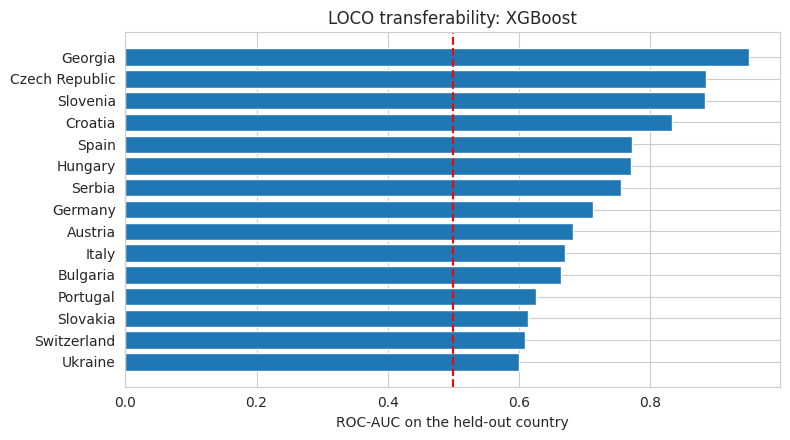

In [38]:
def leave_one_group_out_cls(models, group_series, min_n):
    counts = group_series.value_counts(); eligible = counts[counts >= min_n].index.tolist()
    oof = {m: np.full(len(df_occ), np.nan) for m in models}; rows = []
    for g in eligible:
        te = (group_series == g).values
        for m in models:
            pipe = make_pipe(m, 'cls', params_for('cls', m), y_occ.loc[~te]).fit(X_occ.loc[~te], y_occ.loc[~te])
            oof[m][te] = predict_cls(pipe, X_occ.loc[te])
            r = classification_metrics(y_occ.loc[te], oof[m][te], tau_for(m))
            rows.append({'group': g, 'model': m, 'n': int(te.sum()), 'prevalence': float(y_occ.loc[te].mean()),
                         'ROC-AUC': r['ROC-AUC'], 'PR-AUC': r['PR-AUC'],
                         'Balanced Accuracy': r['Balanced Accuracy'], 'Accuracy': r['Accuracy']})
    return pd.DataFrame(rows), oof

def leave_one_group_out_reg(models, group_series, min_n):
    counts = group_series.value_counts(); eligible = counts[counts >= min_n].index.tolist()
    oof = {m: np.full(len(df_conc), np.nan) for m in models}; rows = []
    for g in eligible:
        te = (group_series == g).values
        for m in models:
            pipe = make_pipe(m, 'reg', params_for('reg', m)).fit(X_conc.loc[~te], y_conc.loc[~te])
            oof[m][te] = predict_reg(pipe, X_conc.loc[te])
            r = regression_metrics(y_conc.loc[te], oof[m][te])
            rows.append({'group': g, 'model': m, 'n': int(te.sum()), 'RMSE': r['RMSE'], 'MAE': r['MAE'],
                         'Bias (log10)': r['Bias (log10)'], 'MAE (ng/L)': r['MAE (ng/L)']})
    return pd.DataFrame(rows), oof

def pooled_cls(oof, models):
    out = {}
    for m in models:
        ok = ~np.isnan(oof[m]); out[m] = classification_metrics(y_occ[ok], oof[m][ok], tau_for(m))
    return pd.DataFrame(out).T[['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC', 'Brier', 'Cal. slope']].astype(float).round(3)

def pooled_reg(oof, models):
    out = {}
    for m in models:
        ok = ~np.isnan(oof[m]); out[m] = regression_metrics(y_conc[ok], oof[m][ok])
    return pd.DataFrame(out).T[['RMSE', 'MAE', 'R2', 'Bias (log10)', 'MAE (ng/L)']].astype(float).round(3)

REG_LOCO_MODELS = ['Linear Regression', 'Random Forest', 'XGBoost', 'CatBoost']
loco_cls_df, loco_cls_oof = leave_one_group_out_cls(LOCO_MODELS, df_occ['country'], MIN_COUNTRY_N)
loco_reg_df, loco_reg_oof = leave_one_group_out_reg(REG_LOCO_MODELS, df_conc['country'], MIN_COUNTRY_N)

print('LOCO, occurrence: pooled over all held-out countries'); print(pooled_cls(loco_cls_oof, LOCO_MODELS))
print('\nLOCO, concentration: pooled over all held-out countries'); print(pooled_reg(loco_reg_oof, REG_LOCO_MODELS))

best_m = pooled_cls(loco_cls_oof, LOCO_MODELS)['PR-AUC'].idxmax()
pc = loco_cls_df[loco_cls_df['model'] == best_m].sort_values('ROC-AUC')
print(f'\nPer-country results for {best_m} (worst ROC-AUC first):'); print(pc.round(3).to_string(index=False))
plt.figure(figsize=(8, max(3, 0.3 * len(pc))))
plt.barh(pc['group'].astype(str), pc['ROC-AUC'].fillna(0.5)); plt.axvline(0.5, color='r', ls='--')
plt.xlabel('ROC-AUC on the held-out country'); plt.title(f'LOCO transferability: {best_m}'); plt.tight_layout(); plt.show()

### Validation 3: temporal validation
Earliest 70 % of the records (by `year`) for training, the next 15 % for validation (to choose τ), the most recent 15 % for testing. Years are never split across partitions. Skipped automatically if the records do not span enough years. Country mix also changes over time, so temporal and spatial effects are partly confounded.

In [39]:
def temporal_masks(years, fr=(0.70, 0.85)):
    years = pd.Series(np.asarray(years, float)); counts = years.value_counts().sort_index()
    cum = (counts.cumsum() / counts.sum())
    y_tr = cum[cum >= fr[0]].index[0]; y_va = cum[cum >= fr[1]].index[0]
    tr = (years <= y_tr).values; va = ((years > y_tr) & (years <= y_va)).values; te = (years > y_va).values
    return tr, va, te, (y_tr, y_va)

TEMPORAL_MODELS = ['Logistic Regression', 'XGBoost', 'CatBoost']
tA = temporal_masks(df_occ['year']); tB = temporal_masks(df_conc['year'])
print('Year cut-offs (train <=, val <=):', tA[3], '| rows (train/val/test) A:', [int(m.sum()) for m in tA[:3]],
      '| B:', [int(m.sum()) for m in tB[:3]])
if min(int(tA[1].sum()), int(tA[2].sum()), int(tB[1].sum()), int(tB[2].sum())) < 20:
    print('Temporal validation skipped: validation/test partitions are too small (records span too few years).')
else:
    rows = []
    for m in TEMPORAL_MODELS:
        pipe = make_pipe(m, 'cls', params_for('cls', m), y_occ[tA[0]]).fit(X_occ[tA[0]], y_occ[tA[0]])
        tau = select_threshold(y_occ[tA[1]], predict_cls(pipe, X_occ[tA[1]]), THRESHOLD_CRITERION)
        r = classification_metrics(y_occ[tA[2]], predict_cls(pipe, X_occ[tA[2]]), tau); r['Model'] = m; rows.append(r)
    print('\nTemporal validation, occurrence (most recent 15 %):')
    print(pd.DataFrame(rows).set_index('Model')[['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC', 'Threshold']].astype(float).round(3))
    rows = []
    for m in ['Linear Regression', 'XGBoost', 'CatBoost']:
        pipe = make_pipe(m, 'reg', params_for('reg', m)).fit(X_conc[tB[0]], y_conc[tB[0]])
        r = regression_metrics(y_conc[tB[2]], predict_reg(pipe, X_conc[tB[2]])); r['Model'] = m; rows.append(r)
    print('\nTemporal validation, concentration (most recent 15 %):')
    print(pd.DataFrame(rows).set_index('Model')[['RMSE', 'MAE', 'R2', 'Bias (log10)', 'MAE (ng/L)']].astype(float).round(3))

Year cut-offs (train <=, val <=): (np.float64(2021.0), np.float64(2022.0)) | rows (train/val/test) A: [1179, 144, 179] | B: [615, 208, 48]

Temporal validation, occurrence (most recent 15 %):
                     Balanced Accuracy  Recall  Precision  ROC-AUC  PR-AUC  \
Model                                                                        
Logistic Regression              0.562   0.208      0.476    0.524   0.353   
XGBoost                          0.554   0.292      0.368    0.506   0.331   
CatBoost                         0.532   0.271      0.325    0.527   0.353   

                     Threshold  
Model                           
Logistic Regression      0.350  
XGBoost                  0.405  
CatBoost                 0.450  

Temporal validation, concentration (most recent 15 %):
                    RMSE    MAE     R2  Bias (log10)  MAE (ng/L)
Model                                                           
Linear Regression  0.566  0.404  0.000         0.114      35.845
X

### Validation 4: water-matrix transfer
Train on the other matrices, test on the withheld one (leave-one-matrix-out, for matrices with at least `MIN_MATRIX_N` rows). The paper's case — train on river water and urban wastewater, test on municipal wastewater — is the row whose matrix name contains "municipal" (marked with ◄). Check the matrix names printed first.

In [40]:
print(df_occ['water_matrix'].value_counts())
MATRIX_MODELS = ['Logistic Regression', 'XGBoost', 'CatBoost']
mx_cls_df, mx_cls_oof = leave_one_group_out_cls(MATRIX_MODELS, df_occ['water_matrix'], MIN_MATRIX_N)
mx_cls_df['paper case'] = np.where(mx_cls_df['group'].str.contains('municipal', case=False), '◄', '')
print('\nMatrix transfer, occurrence (train on other matrices, test on the held-out matrix):')
print(mx_cls_df.round(3).to_string(index=False))

mx_reg_df, _ = leave_one_group_out_reg(['Linear Regression', 'XGBoost', 'CatBoost'], df_conc['water_matrix'], MIN_MATRIX_N)
mx_reg_df['paper case'] = np.where(mx_reg_df['group'].str.contains('municipal', case=False), '◄', '')
print('\nMatrix transfer, concentration:'); print(mx_reg_df.round(3).to_string(index=False))

water_matrix
river/lake      1274
municipal_ww     197
groundwater       31
Name: count, dtype: int64

Matrix transfer, occurrence (train on other matrices, test on the held-out matrix):
       group               model    n  prevalence  ROC-AUC  PR-AUC  Balanced Accuracy  Accuracy paper case
  river/lake Logistic Regression 1274       0.526    0.620   0.613              0.585     0.594           
  river/lake             XGBoost 1274       0.526    0.525   0.538              0.506     0.531           
  river/lake            CatBoost 1274       0.526    0.538   0.546              0.500     0.524           
municipal_ww Logistic Regression  197       0.934    0.668   0.966              0.617     0.751          ◄
municipal_ww             XGBoost  197       0.934    0.644   0.960              0.628     0.706          ◄
municipal_ww            CatBoost  197       0.934    0.572   0.948              0.550     0.426          ◄

Matrix transfer, concentration:
       group             model 

## 3.12 Performance metrics

**Occurrence:** accuracy, precision, recall, F1, ROC-AUC, PR-AUC, balanced accuracy, Brier score, calibration slope (ideal = 1) and calibration plot. **Concentration:** RMSE, MAE, R², prediction bias, and the same errors after back-transforming to ng/L. Thresholds τ were chosen on the validation countries and applied unchanged to the test countries.

In [41]:
def cls_table(split):
    y = yA_va if split == 'val' else yA_te
    t = pd.DataFrame({k: classification_metrics(y, r[split], r['tau']) for k, r in CLS.items()}).T
    return t.astype({c: float for c in t.columns if c not in ('TN', 'FP', 'FN', 'TP')}).round(3)

def reg_table(split):
    y = yB_va if split == 'val' else yB_te
    return pd.DataFrame({k: regression_metrics(y, r[split]) for k, r in REG.items()}).T.astype(float).round(3)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('=== OCCURRENCE, test countries ===');  display(cls_table('test').sort_values('PR-AUC', ascending=False))
print('=== CONCENTRATION, test countries (log10 and ng/L) ==='); display(reg_table('test').sort_values('RMSE'))

=== OCCURRENCE, test countries ===


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,Cal. slope,ECE,Threshold,TN,FP,FN,TP
Random Forest (tuned),0.713,0.701,0.799,0.743,0.770,0.813,0.913,0.174,1.485,0.123,0.450,52.0,27.0,37.0,107.0
Random Forest (default),0.717,0.716,0.819,0.722,0.768,0.808,0.908,0.184,1.330,0.151,0.460,56.0,23.0,40.0,104.0
XGBoost (tuned),0.731,0.675,0.753,0.868,0.806,0.818,0.904,0.188,0.938,0.155,0.240,38.0,41.0,19.0,125.0
CatBoost (tuned),0.735,0.718,0.806,0.778,0.792,0.803,0.899,0.192,0.770,0.144,0.360,52.0,27.0,32.0,112.0
XGBoost (default),0.731,0.763,0.904,0.653,0.758,0.793,0.895,0.208,0.684,0.194,0.440,69.0,10.0,50.0,94.0
CatBoost (default),0.700,0.642,0.733,0.840,0.783,0.772,0.884,0.215,0.589,0.199,0.225,35.0,44.0,23.0,121.0
XGBoost + SMOTE (sensitivity),0.682,0.722,0.884,0.583,0.703,0.782,0.880,0.221,0.594,0.188,0.490,68.0,11.0,60.0,84.0
SVM (tuned),0.709,0.617,0.709,0.931,0.805,0.760,0.863,0.186,0.888,0.095,0.320,24.0,55.0,10.0,134.0
GAM (spline logistic),0.758,0.724,0.796,0.840,0.818,0.788,0.830,0.184,0.558,0.116,0.380,48.0,31.0,23.0,121.0
SVM (default),0.628,0.503,0.647,0.931,0.764,0.568,0.749,0.245,0.297,0.147,0.320,6.0,73.0,10.0,134.0


=== CONCENTRATION, test countries (log10 and ng/L) ===


,RMSE,MAE,R2,Bias (log10),RMSE (ng/L),MAE (ng/L),Bias (ng/L),Median abs. error (ng/L)
Linear Regression,0.580,0.464,0.460,0.090,126.250,46.558,-27.849,4.815
SVR (default),0.602,0.442,0.417,0.142,122.189,43.548,-27.337,5.863
CatBoost (default),0.606,0.495,0.411,0.208,122.225,44.443,-29.658,8.125
CatBoost (tuned),0.646,0.560,0.329,0.210,126.257,45.269,-33.838,7.558
XGBoost (tuned),0.653,0.526,0.316,0.299,115.224,43.709,-19.819,12.987
XGBoost (default),0.661,0.527,0.298,0.328,117.776,42.233,-19.770,13.224
Random Forest (default),0.683,0.537,0.250,0.352,114.670,42.515,-17.814,14.635
Random Forest (tuned),0.689,0.539,0.237,0.353,115.187,42.730,-17.685,15.016
SVR (tuned),0.765,0.678,0.060,0.257,129.362,48.246,-34.684,11.202
Tobit (E[y | quantified]),0.775,0.674,0.036,0.129,126.053,50.363,-25.432,10.301
